# Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

from ISLP import load_data
from ISLP.models import summarize

from sklearn.linear_model import LinearRegression


## **Question 8**

This question involves the use of simple linear regression on the Auto
data set.

- Use the `sm.OLS()` function to perform a simple linear regression with mpg as the response and horsepower as the predictor. Use
the `summarize()` function to print the results. Comment on the output. For example:
    - Is there a relationship between the predictor and the response?
    - How strong is the relationship between the predictor and the response?
    - Is the relationship between the predictor and the response positive or negative?
    - What is the predicted mpg associated with a horsepower of 98? What are the associated 95 % confidence and prediction intervals?
- Plot the response and the predictor in a new set of axesax. Use the `ax.axline()` method or the `abline()` function defined in the lab to display the least squares regression line.
- Produce some of diagnostic plots of the least squares regression fit as described in the lab. Comment on any problems you see with the fit. 

In [2]:
auto = load_data("auto")
auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


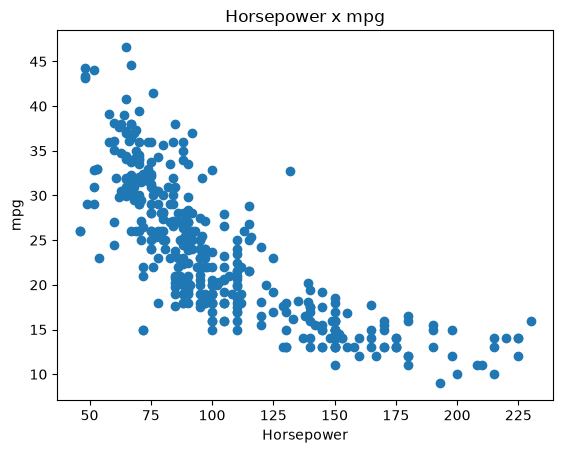

In [3]:
plt.scatter(auto["horsepower"], auto["mpg"])
plt.title("Horsepower x mpg")
plt.ylabel("mpg")
plt.xlabel("Horsepower")
plt.show()

In [4]:
y = auto["mpg"]
X = auto["horsepower"]
X = sm.add_constant(X)
model = sm.OLS(y, X)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     599.7
Date:                Tue, 06 Oct 2026   Prob (F-statistic):           7.03e-81
Time:                        10:43:21   Log-Likelihood:                -1178.7
No. Observations:                 392   AIC:                             2361.
Df Residuals:                     390   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         39.9359      0.717     55.660      0.0

In [5]:
print(summarize(results))

               coef  std err       t  P>|t|
const       39.9359    0.717  55.660    0.0
horsepower  -0.1578    0.006 -24.489    0.0


i) yes, there is a relationship between predictor and response

ii) $R^2$ shows that approximately 60% of the variance is explained by the predictor

iii) There is a negative relationship between the predictor and the response, meaning they move in opposite directions. A higher horsepower results in lower mpg

iv) What is the predicted mpg associated with a horsepower of 98? What are the associated 95% confidence and prediction intervals?

In [6]:
hp = 98.0
predic_values = pd.DataFrame(
    {"const": [1.0], 
     "horsepower": [hp]}
)

newPredictions = results.get_prediction(predic_values)

print(f"For a horsepower of {hp}, the predicted mpg is: {newPredictions.predicted_mean[0]:.3f}")

print(f"\nThe 95% confidence interval is: {newPredictions.conf_int()[0]}")

print(f"\nThe 95% prediction interval is: {newPredictions.conf_int(obs=True)[0]}")

For a horsepower of 98.0, the predicted mpg is: 24.467

The 95% confidence interval is: [23.97307896 24.96107534]

The 95% prediction interval is: [14.80939607 34.12475823]


(b) Plot the response and the predictor in a new set of axes ax. Use the `ax.axline()` method or the `abline()` function defined in the lab to display the least squares regression line.

In [7]:
const = results.params["const"]
hp = results.params["horsepower"]

x = np.arange(50, 150)

y = const + hp * x



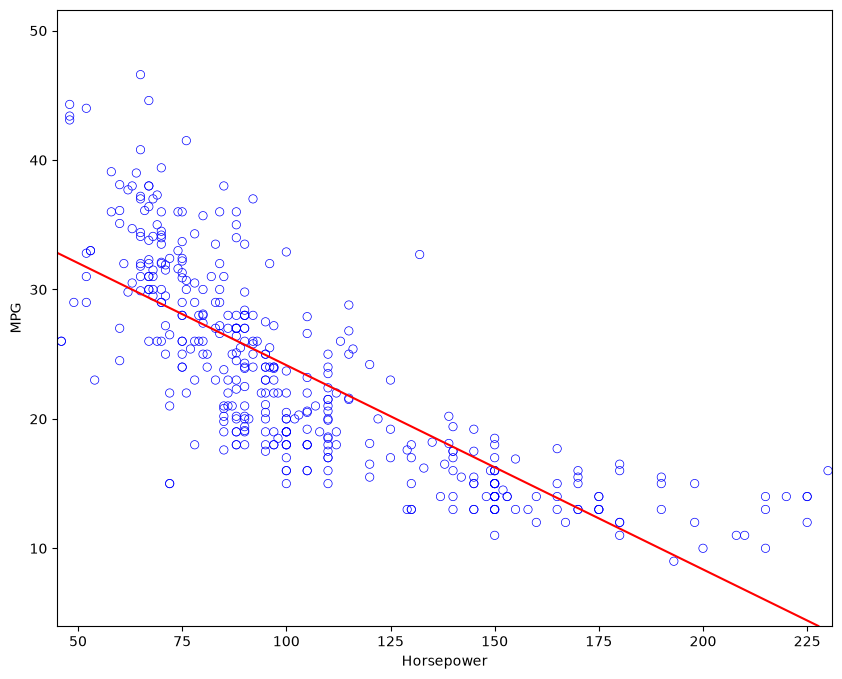

In [8]:
fig, axs = plt.subplots(ncols=1, nrows=1, figsize=(10, 8))

x_min = auto["horsepower"].min() - 1
x_max = auto["horsepower"].max() + 1

y_min = auto["mpg"].min() - 5
y_max = auto["mpg"].max() + 5


axs.set(xlim=(x_min, x_max), ylim=(y_min, y_max))
axs.axline((0, const), slope=hp, color="r")
axs.scatter(auto["horsepower"], auto["mpg"], marker="o", facecolors="none", edgecolors="b", linewidth=0.5)

axs.set_ylabel("MPG")
axs.set_xlabel("Horsepower")
plt.show()

## 9. This question involves the use of multiple linear regression on the Auto data set.

(a) Produce a scatterplot matrix which includes all of the variables in the data set

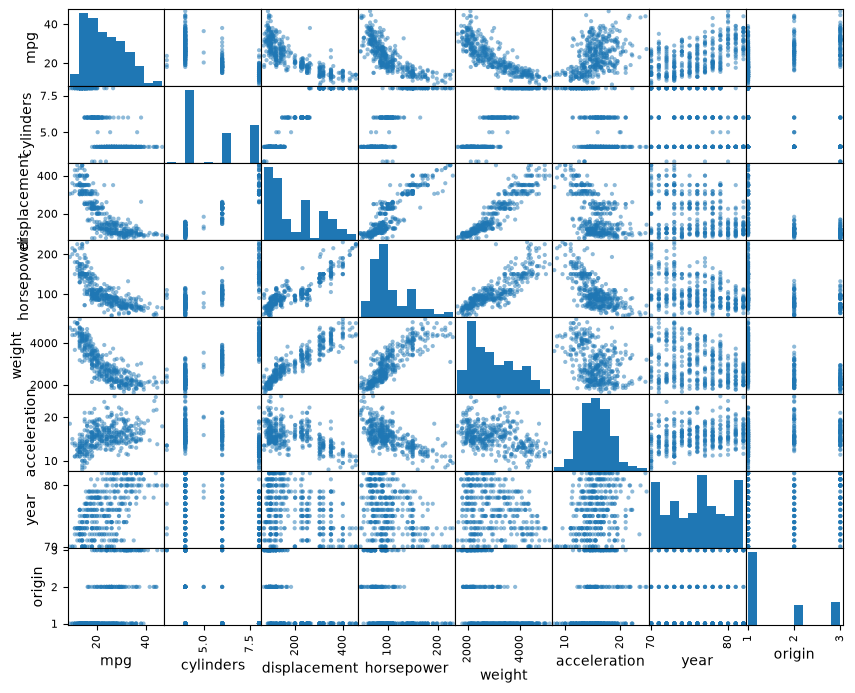

In [9]:
pd.plotting.scatter_matrix(auto, figsize=(10, 8))
plt.show()

(b) Compute the matrix of correlations between the variables using the DataFrame.corr() method.

In [10]:
auto.drop(columns=["name"]).corr()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
mpg,1.000000,-0.777618,-0.805127,-0.778427,-0.832244,0.423329,0.580541,0.565209
cylinders,-0.777618,1.000000,0.950823,0.842983,0.897527,-0.504683,-0.345647,-0.568932
displacement,-0.805127,0.950823,1.000000,0.897257,0.932994,-0.543800,-0.369855,-0.614535
horsepower,-0.778427,0.842983,0.897257,1.000000,0.864538,-0.689196,-0.416361,-0.455171
weight,-0.832244,0.897527,0.932994,0.864538,1.000000,-0.416839,-0.309120,-0.585005
acceleration,0.423329,-0.504683,-0.543800,-0.689196,-0.416839,1.000000,0.290316,0.212746
year,0.580541,-0.345647,-0.369855,-0.416361,-0.309120,0.290316,1.000000,0.181528
origin,0.565209,-0.568932,-0.614535,-0.455171,-0.585005,0.212746,0.181528,1.000000


(c) Use the sm.OLS() function to perform a multiple linear regression with mpg as the response and all other variables except name as the predictors. Use the summarize() function to print the results.
Comment on the output. For instance:

    - Is there a relationship between the predictors and the response?
    Use the anova_lm() function from statsmodels to answer this question.

    - Which predictors appear to have a statistically significant relationship to the response?

    - What does the coefficient for the year variable suggest?

In [11]:
y = auto["mpg"]
x = auto.drop(columns=["mpg", "name"])

x = sm.add_constant(x)

model = sm.OLS(y, x)
results = model.fit()

In [12]:
print(results.summary2())

                 Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.818    
Dependent Variable: mpg              AIC:                2062.9495
Date:               2026-10-06 10:43 BIC:                2094.7196
No. Observations:   392              Log-Likelihood:     -1023.5  
Df Model:           7                F-statistic:        252.4    
Df Residuals:       384              Prob (F-statistic): 2.04e-139
R-squared:          0.821            Scale:              11.073   
------------------------------------------------------------------
                  Coef.   Std.Err.    t    P>|t|   [0.025   0.975]
------------------------------------------------------------------
const            -17.2184   4.6443 -3.7074 0.0002 -26.3499 -8.0870
cylinders         -0.4934   0.3233 -1.5261 0.1278  -1.1290  0.1422
displacement       0.0199   0.0075  2.6474 0.0084   0.0051  0.0347
horsepower        -0.0170   0.0138 -1.2295 0.2196  -0.0441  0.0102
weight       

In [13]:
summarize(results)

,coef,std err,t,P>|t|
const,-17.2184,4.644,-3.707,0.000
cylinders,-0.4934,0.323,-1.526,0.128
displacement,0.0199,0.008,2.647,0.008
horsepower,-0.0170,0.014,-1.230,0.220
weight,-0.0065,0.001,-9.929,0.000
acceleration,0.0806,0.099,0.815,0.415
year,0.7508,0.051,14.729,0.000
origin,1.4261,0.278,5.127,0.000


In [14]:
model = ols('auto["mpg"] ~ auto.drop(columns=["mpg", "name"])', data=auto)
results = model.fit()
anova_table = anova_lm(results)
print(anova_table)
anova_table

                                       df        sum_sq     mean_sq  \
auto.drop(columns=["mpg", "name"])    7.0  19566.780939  2795.25442   
Residual                            384.0   4252.212530    11.07347   

                                             F         PR(>F)  
auto.drop(columns=["mpg", "name"])  252.428045  2.037106e-139  
Residual                                   NaN            NaN  


,df,sum_sq,mean_sq,F,PR(>F)
"auto.drop(columns=[""mpg"", ""name""])",7.0,19566.780939,2795.25442,252.428045,2.037106e-139
Residual,384.0,4252.212530,11.07347,NaN,NaN


# **Working with the Auto dataset**

In [15]:
auto = load_data('Auto')
auto.dropna(inplace=True)
auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
name,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1
ford torino,17.0,8,302.0,140,3449,10.5,70,1


In [16]:
for x in ['cylinders', 'year', 'origin']:
    print(f"{x}: {auto[x].unique()}", "\n")

cylinders: [8 4 6 3 5] 

year: [70 71 72 73 74 75 76 77 78 79 80 81 82] 

origin: [1 3 2] 



In [17]:
for x in auto.columns:
    print(f"Max of {x}: {auto[x].max():.2f}")
    print(f"Min of {x}: {auto[x].min():.2f}")
    print(f"Mean of {x}: {auto[x].mean():.2f}")
    print(f"Std of {x}: {auto[x].std():.2f}\n")

Max of mpg: 46.60
Min of mpg: 9.00
Mean of mpg: 23.45
Std of mpg: 7.81

Max of cylinders: 8.00
Min of cylinders: 3.00
Mean of cylinders: 5.47
Std of cylinders: 1.71

Max of displacement: 455.00
Min of displacement: 68.00
Mean of displacement: 194.41
Std of displacement: 104.64

Max of horsepower: 230.00
Min of horsepower: 46.00
Mean of horsepower: 104.47
Std of horsepower: 38.49

Max of weight: 5140.00
Min of weight: 1613.00
Mean of weight: 2977.58
Std of weight: 849.40

Max of acceleration: 24.80
Min of acceleration: 8.00
Mean of acceleration: 15.54
Std of acceleration: 2.76

Max of year: 82.00
Min of year: 70.00
Mean of year: 75.98
Std of year: 3.68

Max of origin: 3.00
Min of origin: 1.00
Mean of origin: 1.58
Std of origin: 0.81



In [18]:
mask = [(i < 10) or (i > 84) for i in range(len(auto))]
auto_filtered = auto.iloc[mask]

for x in auto_filtered.columns:
    print(f"Max of {x}: {auto_filtered[x].max():.2f}")
    print(f"Min of {x}: {auto_filtered[x].min():.2f}")
    print(f"Mean of {x}: {auto_filtered[x].mean():.2f}")
    print(f"Std of {x}: {auto_filtered[x].std():.2f}\n")



Max of mpg: 46.60
Min of mpg: 11.00
Mean of mpg: 24.37
Std of mpg: 7.87

Max of cylinders: 8.00
Min of cylinders: 3.00
Mean of cylinders: 5.38
Std of cylinders: 1.66

Max of displacement: 455.00
Min of displacement: 68.00
Mean of displacement: 187.88
Std of displacement: 100.17

Max of horsepower: 230.00
Min of horsepower: 46.00
Mean of horsepower: 101.00
Std of horsepower: 36.00

Max of weight: 4997.00
Min of weight: 1649.00
Mean of weight: 2938.85
Std of weight: 811.64

Max of acceleration: 24.80
Min of acceleration: 8.50
Mean of acceleration: 15.70
Std of acceleration: 2.72

Max of year: 82.00
Min of year: 70.00
Mean of year: 77.12
Std of year: 3.13

Max of origin: 3.00
Min of origin: 1.00
Mean of origin: 1.60
Std of origin: 0.82



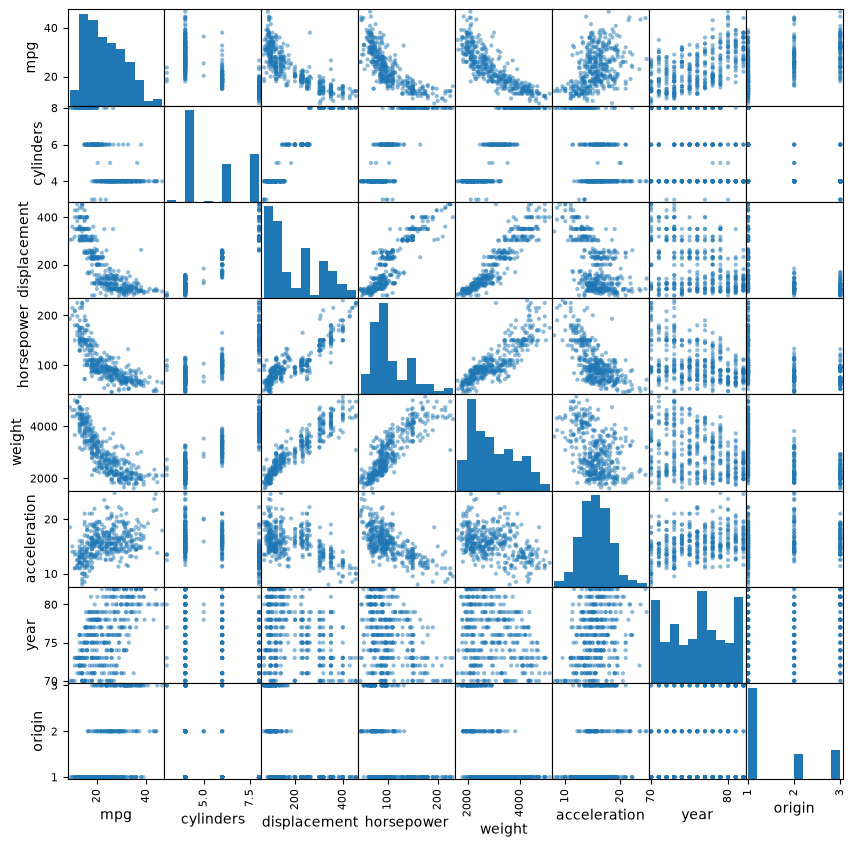

In [19]:
pd.plotting.scatter_matrix(auto, figsize=(10, 10));

# **Working with the Boston dataset**

In [20]:
boston = load_data('Boston')
boston.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [21]:
boston.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  lstat    506 non-null    float64
 12  medv     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


In [22]:
boston["chas"].sum()

np.int64(35)

What is the median pupil-teacher ratio among the towns in this
data set?

In [23]:
resp = boston["ptratio"].median()
print(f"The median pupil-teacher ratio in the Boston dataset is: {resp:.2f}")

The median pupil-teacher ratio in the Boston dataset is: 19.05


Which suburb of Boston has lowest median value of owner-occupied homes? What are the values of the other predictors for that suburb, and how do those values compare to the overall ranges for those predictors? Comment on your findings.

In [24]:
boston["age"].median()

np.float64(77.5)

In [25]:
import scipy.stats as stats

# Given parameters
beta1_hat = 0.5
se_beta1 = 0.2
alpha = 0.05

# Critical Z-value for a two-tailed test at alpha = 0.05
z_crit = stats.norm.ppf(1 - alpha / 2)

# Calculate upper and lower bounds for b (95% CI)
b_max = beta1_hat + z_crit * se_beta1
b_min = beta1_hat - z_crit * se_beta1

print(f"Critical Z-value: {z_crit:.4f}")
print(f"Non-rejection region for b: [{b_min:.4f}, {b_max:.4f}]")
print(f"Largest value of b (2 significant digits): {b_max:.2g}")

Critical Z-value: 1.9600
Non-rejection region for b: [0.1080, 0.8920]
Largest value of b (2 significant digits): 0.89


In [26]:
stats.norm.sf

<bound method rv_continuous.sf of <scipy.stats._continuous_distns.norm_gen object at 0x117efcc20>>

In [27]:
def logReg(beta0, beta1, beta2, x1, x2):
    eq = beta0 + beta1 * x1 + beta2 * x2
    return np.exp(eq) / (1 + np.exp(eq))

In [28]:
x = logReg(-6, 0.05, 1, 40, 3.5)
print(f"Prob = {x:.2f}")

Prob = 0.38


In [29]:
beta0 = -6
beta1 = 0.05
beta2 = 1
x2 = 3.5
x1 = (-beta0 - beta2 * x2) / beta1
print(x1)

50.0
